# MaskFormer Training on Welding Robot Data

End-to-end training pipeline for `GLCAnomalyMaskFormer` using the mock welding robot dataset.

**Pipeline:**
1. Load and explore CSV (1.84M timesteps, 3 sensors, 250ms intervals)
2. Group consecutive timesteps into macro-windows (seq_len=240), with padding
3. Build `RawWindowDataset` with robot/program indices
4. Initialize MaskFormer (num_sensors=3)
5. Train with `MaskFormerTrainerRunner`
6. Visualize training curves

In [1]:
# %% Imports
import sys
import os
import json
import math
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# Add project root to path
project_root = Path.cwd().parent.parent.resolve()
print(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from app.anomaly_detection.utils import set_random_seed
set_random_seed(42)
print("Random seed set to 42")

from app.anomaly_detection.models import (
    create_model,
    filter_model_kwargs,
    MaskFormerModels,
)
from app.anomaly_detection.training.maskformer_trainer import (
    MaskFormerTrainerRunner,
)
from app.anomaly_detection.training.datasets import RawWindowDataset

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


/home/trietlm/TED-Hackathon-Agent
Random seed set to 42
All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load and Explore Data

In [2]:
# Load the full CSV
CSV_PATH = project_root / "data" / "train_welding_robot.csv"
print(f"Reading {CSV_PATH}...")

import csv
with open(CSV_PATH, "r") as f:
    reader = csv.DictReader(f)
    rows = list(reader)

print(f"Total rows: {len(rows):,}")
print(f"Columns: {list(rows[0].keys())}")

# Sensor columns
SENSOR_COLS = ["wire_feed_speed_mm_min", "wire_temperature_c", "welding_current_a"]
print(f"Sensor columns: {SENSOR_COLS}")

# Quick stats
robot_codes = sorted(set(r["robot_code"] for r in rows))
program_nums = sorted(set(r["program_number"] for r in rows))
phases = sorted(set(r["phase"] for r in rows))
print(f"Robot codes: {robot_codes}")
print(f"Program numbers: {program_nums}")
print(f"Phases: {phases}")
print(f"Example row: {dict(list(rows[0].items())[:6])}")


Reading /home/trietlm/TED-Hackathon-Agent/data/train_welding_robot.csv...
Total rows: 10,413,311
Columns: ['robot_code', 'start_time', 'program_number', 'infer_recorded_date', 'serial_number', 'phase', 'wire_feed_speed_mm_min', 'wire_temperature_c', 'welding_current_a', 'timestamp']
Sensor columns: ['wire_feed_speed_mm_min', 'wire_temperature_c', 'welding_current_a']
Robot codes: ['0', '1', '2', '3']
Program numbers: ['0', '1', '10', '11', '12', '13', '14', '15', '2', '3', '4', '5', '6', '7', '8', '9']
Phases: ['active', 'idle', 'rampup', 'shutdown', 'winddown']
Example row: {'robot_code': '0', 'start_time': '2025-07-01 08:00:00', 'program_number': '3', 'infer_recorded_date': '2025-07-01 08:00:00.000', 'serial_number': '1', 'phase': 'idle'}


## 2. Merge into Macro-Windows with Padding

Each "file" = unique `(robot_code, start_time, program_number)` group.
Rows within a group are ordered by `serial_number`.
We extract the 3 sensor values, zero-pad to `seq_len=240` if shorter, or slice if longer.

In [3]:
SEQ_LEN = 240  # MaskFormer default macro-window length
STRIDE = 80  # Set stride here, you can change this
NUM_SENSORS = 3  # wire_feed_speed, welding_voltage, welding_current

# Group rows by (robot_code, start_time, program_number)
groups = defaultdict(list)
for r in rows:
    # Ensure start_time is a string
    key = (str(r["robot_code"]), str(r["start_time"]), str(r["program_number"]))
    groups[key].append(r)

print(f"Total groups (files): {len(groups)}")

# Build windows: each group → one file-window [C, T]
windows_list = []
robot_idx_list = []
program_idx_list = []
group_keys = []

# Build robot and program codebooks
all_robot_codes = sorted(set(str(r["robot_code"]) for r in rows))
all_program_nums = sorted(set(str(r["program_number"]) for r in rows))
robot_to_idx = {code: i for i, code in enumerate(all_robot_codes)}
program_to_idx = {pn: i for i, pn in enumerate(all_program_nums)}

print(f"Robot codebook: {len(robot_to_idx)} codes → indices 0..{len(robot_to_idx)-1}")
print(f"Program codebook: {len(program_to_idx)} programs → indices 0..{len(program_to_idx)-1}")

for key, group_rows in groups.items():
    # Sort by serial_number (ascending)
    group_rows.sort(key=lambda x: int(x["serial_number"]))
    
    # Extract sensor values as float array [T, C]
    file_arr = np.array(
        [[float(r[col]) for col in SENSOR_COLS] for r in group_rows],
        dtype=np.float32,
    )  # [T, C]
    
    T = file_arr.shape[0]
    
    if T >= SEQ_LEN:
        # Extract multiple windows with the given stride
        for start_idx in range(0, T - SEQ_LEN + 1, STRIDE):
            window = file_arr[start_idx : start_idx + SEQ_LEN, :].T  # [C, T]
            windows_list.append(window)
            robot_idx_list.append(robot_to_idx[key[0]])
            program_idx_list.append(program_to_idx[key[2]])
            group_keys.append(key)
        
        # Optionally, handle the remaining tail by padding if needed
        # (Often ignored if the tail is too short and already covered by a previous overlapped window)
        tail_start = (T - SEQ_LEN) // STRIDE * STRIDE + STRIDE
        if tail_start < T and T - tail_start > 0:
            tail = file_arr[tail_start:, :]
            pad = np.zeros((SEQ_LEN - tail.shape[0], NUM_SENSORS), dtype=np.float32)
            window = np.vstack([tail, pad]).T
            windows_list.append(window)
            robot_idx_list.append(robot_to_idx[key[0]])
            program_idx_list.append(program_to_idx[key[2]])
            group_keys.append(key)
    else:
        # Zero-pad to SEQ_LEN
        pad = np.zeros((SEQ_LEN - T, NUM_SENSORS), dtype=np.float32)
        window = np.vstack([file_arr, pad]).T  # [C, T]
        windows_list.append(window)
        robot_idx_list.append(robot_to_idx[key[0]])
        program_idx_list.append(program_to_idx[key[2]])
        group_keys.append(key)

# Stack into arrays
windows_arr = np.stack(windows_list, axis=0)  # [N, C, T]
robot_arr = np.array(robot_idx_list, dtype=np.int64)
program_arr = np.array(program_idx_list, dtype=np.int64)

print(f"\nWindows shape: {windows_arr.shape}  [N, C={NUM_SENSORS}, T={SEQ_LEN}]")
print(f"Robot indices shape: {robot_arr.shape}, unique: {np.unique(robot_arr)}")
print(f"Program indices shape: {program_arr.shape}, unique: {np.unique(program_arr)}")
print(f"Sensor value range: [{windows_arr.min():.4f}, {windows_arr.max():.4f}]")

Total groups (files): 29042
Robot codebook: 4 codes → indices 0..3
Program codebook: 16 programs → indices 0..15

Windows shape: (90653, 3, 240)  [N, C=3, T=240]
Robot indices shape: (90653,), unique: [0 1 2 3]
Program indices shape: (90653,), unique: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
Sensor value range: [-8.2000, 362.9000]


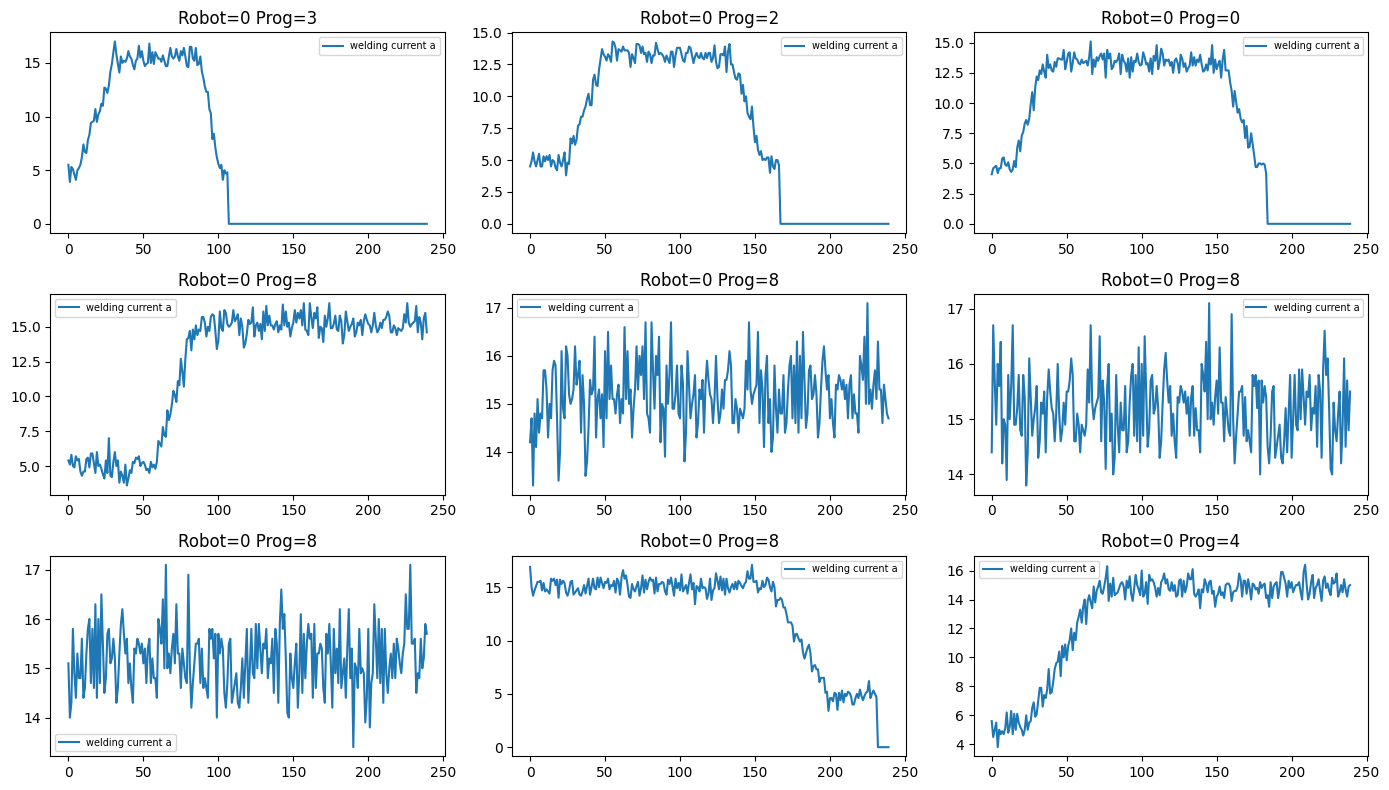

In [4]:
# Quick sanity: plot a few file-windows
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for i in range(3):
    for j in range(3):
        idx = i * 3 + j
        ax = axes[i, j]
        w = windows_arr[idx]
        for s in range(NUM_SENSORS):
            if s != 2:
                continue
            ax.plot(w[s], label=SENSOR_COLS[s].replace("_", " "))
        ax.set_title(f"Robot={group_keys[idx][0]} Prog={group_keys[idx][2]}")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


### Window Generation Test

Let's test if the mathematically expected number of windows matches what was extracted, and print out the starting serial number for each stride offset.

In [5]:
# Test cell to verify the number of windows and starting serials for a sampled file

# Let's take the first file from our groups dictionary
sample_key = list(groups.keys())[2]
sample_group = groups[sample_key]
T = len(sample_group)

print(f"Testing for file (Robot={sample_key[0]}, Program={sample_key[2]})")
print(f"Total timesteps (rows) in file: T = {T}")
print(f"SEQ_LEN = {SEQ_LEN}, STRIDE = {STRIDE}")

# Mathematical calculation for expected number of windows
if T >= SEQ_LEN:
    expected_full_windows = (T - SEQ_LEN) // STRIDE + 1
    tail_start = expected_full_windows * STRIDE
    expected_tail = 1 if tail_start < T and (T - tail_start > 0) else 0
    expected_total_windows = expected_full_windows + expected_tail
else:
    expected_full_windows = 0
    expected_tail = 1
    expected_total_windows = 1

print(f"Expected Full Windows: {expected_full_windows}")
print(f"Expected Tail Windows: {expected_tail}")
print(f"Expected Total Windows: {expected_total_windows}")

# Let's count how many windows actually exist for this key in the lists we generated
actual_windows_idx = [i for i, k in enumerate(group_keys) if k == sample_key]
actual_total_windows = len(actual_windows_idx)

print(f"Actual Total Windows Gen'd: {actual_total_windows}")
assert actual_total_windows == expected_total_windows, "Mismatch in window counts!"

print("\nChecking Starting Serials / Indices:")
if T >= SEQ_LEN:
    for w_idx in range(expected_full_windows):
        start_idx = w_idx * STRIDE
        start_serial = int(sample_group[start_idx]["serial_number"])
        print(f"  Window {w_idx}: starts at index {start_idx}, serial_number {start_serial}")
    
    if expected_tail:
        tail_start = expected_full_windows * STRIDE
        start_serial = int(sample_group[tail_start]["serial_number"])
        print(f"  Tail Window: starts at index {tail_start}, serial_number {start_serial}")
else:
    start_serial = int(sample_group[0]["serial_number"])
    print(f"  Single Padded Window: starts at index 0, padding up to {SEQ_LEN}, serial_number {start_serial}")

print("\nTest passed successfully! 🎉")

Testing for file (Robot=0, Program=0)
Total timesteps (rows) in file: T = 184
SEQ_LEN = 240, STRIDE = 80
Expected Full Windows: 0
Expected Tail Windows: 1
Expected Total Windows: 1
Actual Total Windows Gen'd: 1

Checking Starting Serials / Indices:
  Single Padded Window: starts at index 0, padding up to 240, serial_number 1

Test passed successfully! 🎉


## 3. Create Dataset and DataLoader

In [6]:
# Split into train/val (80/20)
N = len(windows_arr)
indices = np.random.permutation(N)
split = int(0.8 * N)
train_idx = indices[:split]
val_idx = indices[split:]

train_dataset = RawWindowDataset(
    windows=windows_arr[train_idx],
    robot_indices=robot_arr[train_idx],
    program_indices=program_arr[train_idx],
)
val_dataset = RawWindowDataset(
    windows=windows_arr[val_idx],
    robot_indices=robot_arr[val_idx],
    program_indices=program_arr[val_idx],
)

print(f"Train files: {len(train_dataset)}")
print(f"Val files:   {len(val_dataset)}")
print(f"Sample output keys: {list(train_dataset[0].keys())}")
print(f"  input shape: {train_dataset[0]['input'].shape}")
print(f"  robot_idx:   {train_dataset[0]['robot_idx']}")
print(f"  program_idx: {train_dataset[0]['program_idx']}")


Train files: 72522
Val files:   18131
Sample output keys: ['input', 'robot_idx', 'program_idx']
  input shape: torch.Size([3, 240])
  robot_idx:   1
  program_idx: 5


## 4. Initialize MaskFormer Model

Key config adjustments for welding data:
- `num_sensors=3` (wire_feed_speed, welding_voltage, welding_current)
- `num_robots` set to actual unique robot count
- `num_programs` set to actual unique program count

In [7]:
num_unique_robots = len(np.unique(robot_arr))
num_unique_programs = len(np.unique(program_arr))

config = {
    "num_sensors": NUM_SENSORS,
    "seq_len": SEQ_LEN,
    "num_robots": num_unique_robots,
    "num_programs": num_unique_programs,
    "use_context_embeddings": True,
    "d_model": 128,
    "transformer_layers": 4,
    "transformer_heads": 4,
    "mask_ratio": 0.3,
    "lambda_assoc": 2.0,
    "lambda_orth": 0.05,
}

model = create_model(MaskFormerModels.GLC_ANOMALY_MASKFORMER, config)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: {model.name}")
print(f"Config: num_sensors={config['num_sensors']}, seq_len={config['seq_len']}, "
      f"d_model={config['d_model']}, num_robots={config['num_robots']}, "
      f"num_programs={config['num_programs']}")
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")


Model: GLCAnomalyMaskFormer
Config: num_sensors=3, seq_len=240, d_model=128, num_robots=4, num_programs=16
Total params: 823,088
Trainable params: 823,088


## 5. Initialize Trainer and Train

In [8]:
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-4

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

print(f"Batches per epoch: train={len(train_loader)}, val={len(val_loader)}")

# Build runner and train
runner = MaskFormerTrainerRunner(model_or_config=model)
history = runner.train(
    train_loader=list(train_loader),
    val_loader=list(val_loader),
    epochs=EPOCHS,
    lr=LR,
)

print("\nTraining complete!")
print(f"Final loss: {history['loss'][-1]:.4f}")
print(f"Final recon_loss: {history['recon_loss'][-1]:.4f}")
print(f"Final assoc_loss_min: {history['assoc_loss_min'][-1]:.4f}")
print(f"Final sigma_mean: {history['sigma_mean'][-1]:.3f}")


Batches per epoch: train=2266, val=567


Epochs:   0%|          | 0/30 [00:00<?, ?epoch/s]

Epoch 1/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 2/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 3/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

...

Epoch 27/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 28/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 29/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 30/30:   0%|          | 0/2266 [00:00<?, ?batch/s]

Epoch 30/30 — loss: -40.7382  recon: 0.3238  assoc_min: 20.5328  sigma: 11.566

Training complete!
Final loss: -40.7382
Final recon_loss: 0.3238
Final assoc_loss_min: 20.5328
Final sigma_mean: 11.566


## 6. Visualize Training Curves

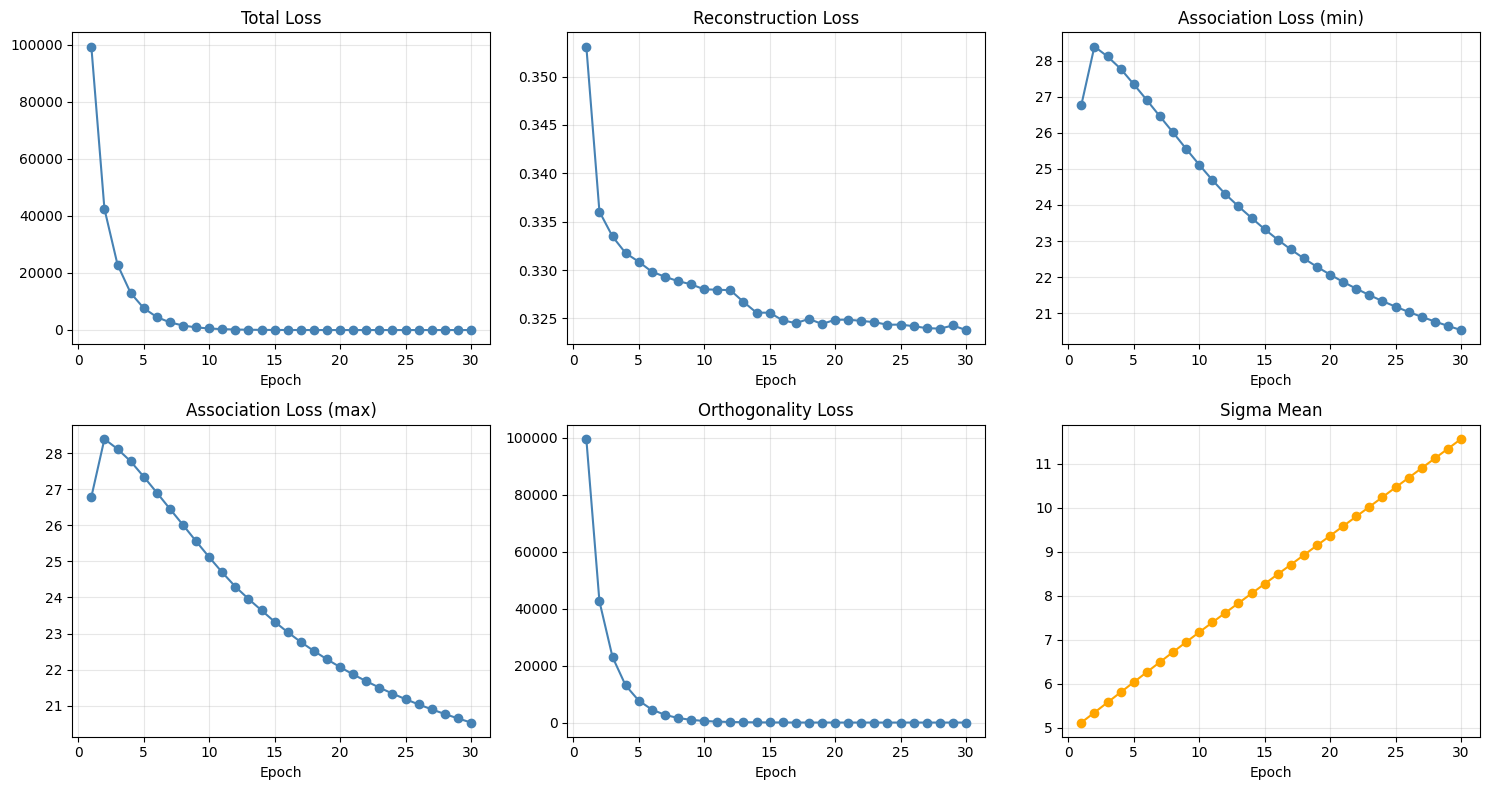

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
epochs = range(1, len(history["loss"]) + 1)

metrics = [
    ("loss", "Total Loss", None),
    ("recon_loss", "Reconstruction Loss", None),
    ("assoc_loss_min", "Association Loss (min)", None),
    ("assoc_loss_max", "Association Loss (max)", None),
    ("orth_loss", "Orthogonality Loss", None),
    ("sigma_mean", "Sigma Mean", "orange"),
]
for ax, (key, title, color) in zip(axes.flat, metrics):
    ax.plot(epochs, history[key], marker="o", color=color or "steelblue")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Save Model Checkpoint

In [10]:
# Save model checkpoint using BaseAnomalyDetectionModel.save_manual_checkpoint
ckpt_dir = project_root / "artifacts" / "maskformer_checkpoint"
model.save_manual_checkpoint(
    epoch=EPOCHS,
    val_loss=history["loss"][-1],
    folder_path=str(ckpt_dir),
    is_best=True,
)
print(f"Model state_dict saved to {ckpt_dir / f'model_{model.name}_best.pt'}")
print(f"Model metadata saved to {ckpt_dir / f'metadata_{model.name}_best.json'}")

# Also save training history and codebooks separately
extra = {
    "history": history,
    "robot_codebook": robot_to_idx,
    "program_codebook": program_to_idx,
}
with open(ckpt_dir / "training_extra.json", "w") as f:
    json.dump(extra, f, indent=2, default=str)
print(f"Training extras (history, codebooks) saved to {ckpt_dir / 'training_extra.json'}")
print("Done! 🎉")


Model state_dict saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint/model_GLCAnomalyMaskFormer_best.pt
Model metadata saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint/metadata_GLCAnomalyMaskFormer_best.json
Training extras (history, codebooks) saved to /home/trietlm/TED-Hackathon-Agent/artifacts/maskformer_checkpoint/training_extra.json
Done! 🎉
